# Blockpose detector: PCL baseline &rarr; FK prior &rarr; DINO priors

The detector has four evidence stages, added in this order. Each is measured
independently against the 62 approved blocks in
`config/annotated_snapshots_seibersdorf.yaml` (25 annotated snapshots,
`data/seibersdorf_dataset`), unless noted otherwise. **`dino_proposer` and
`dino_verifier` are trained and measured standalone here; they are not yet
wired into the C++ detector's candidate pool** (see
`docs/dino-rgb-prior-ros-integration.md` for the target integration and
`## Status` at the end of this notebook).

Sources for every number below: `experiments/detector_cluster_failures.md`,
`experiments/pose_quality_and_partial_observation.md`,
`out/dino_verifier_checkpoint_seibersdorf/train_summary.json`. This notebook
regenerates every figure from committed snapshot data and calibration &mdash;
no trained checkpoint or GPU is required to run it. The shipped checkpoints
themselves live in `models/production/`.

In [1]:
import sys
from pathlib import Path

def find_repo_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").is_file() and (candidate / "python/blockpose").is_dir():
            return candidate
    raise RuntimeError("Could not locate repository root from notebook working directory")

REPO_ROOT = find_repo_root()
for p in (REPO_ROOT / "python", REPO_ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from blockpose.annotations import load_annotations
from blockpose.io import load_snapshot, load_tf_snapshot, load_camera_model
from experiments.rgb_region_prior import export as region_export


def box_edges(pose):
    # World-frame cuboid edges from a blockpose.pose.BlockPose.
    half = np.asarray(pose.dims, dtype=float) / 2.0
    corners = np.array(
        [[x, y, z] for x in (-half[0], half[0]) for y in (-half[1], half[1]) for z in (-half[2], half[2])]
    )
    corners = (pose.rotation @ corners.T).T + pose.position
    return [
        (corners[i], corners[j])
        for i in range(8) for j in range(i + 1, 8)
        if bin(i ^ j).count("1") == 1
    ]


def draw_pose(ax, pose, colour, style="-", label=None, plotted=None, lw=2.2):
    for k, (start, end) in enumerate(box_edges(pose)):
        ax.plot(*zip(start, end), color=colour, linestyle=style, linewidth=lw,
                label=label if k == 0 else None)
        if plotted is not None:
            plotted.append(np.vstack([start, end]))


def set_equal_3d(ax, arrays, padding=0.12, min_span=0.5):
    pts = np.vstack([np.asarray(a, float).reshape(-1, 3) for a in arrays if np.asarray(a).size])
    pts = pts[np.all(np.isfinite(pts), axis=1)]
    low, high = pts.min(axis=0), pts.max(axis=0)
    span = max(float(np.max(high - low)), min_span) * (1 + 2 * padding)
    center = (low + high) / 2
    ax.set_xlim(center[0] - span / 2, center[0] + span / 2)
    ax.set_ylim(center[1] - span / 2, center[1] + span / 2)
    ax.set_zlim(center[2] - span / 2, center[2] + span / 2)
    spans = np.full(3, span)
    ax.set_box_aspect(spans)


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## Architecture

RGB (`dino_proposer`, `dino_verifier`) and the FK/gripper prior are **bounded
evidence**, never an independent pose source. The C++ PCL core remains sole
owner of every candidate and every accepted pose; RGB proposes regions and
re-ranks fitted candidates, it never emits one. See
`docs/dino-rgb-prior-ros-integration.md` for the full contract.

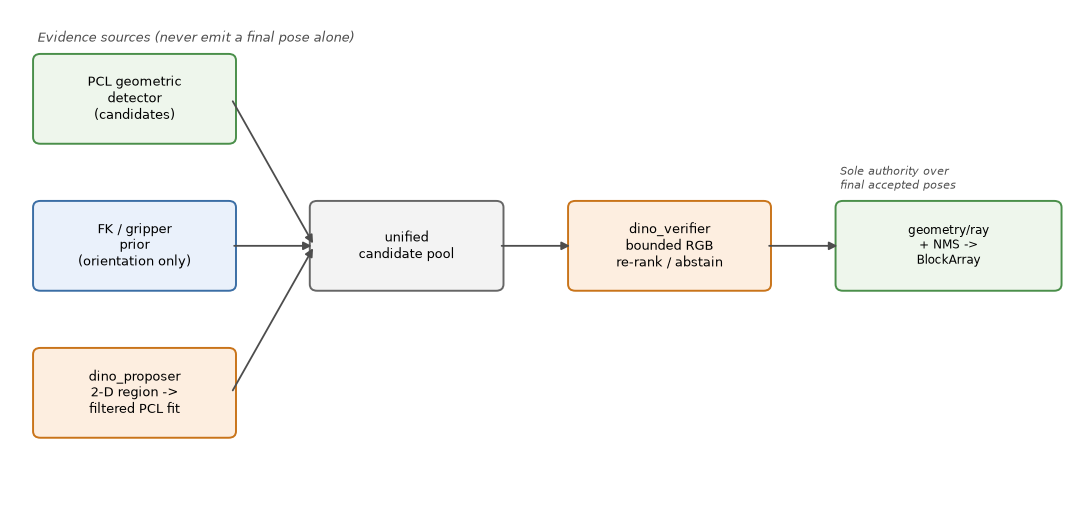

In [2]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.set_xlim(0, 11.6); ax.set_ylim(0, 6); ax.axis("off")

def _box(x, y, w, h, text, color, edge, fontsize=9.2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.08",
                                 linewidth=1.4, edgecolor=edge, facecolor=color))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fontsize)
    return (x, y, w, h)

def _arrow(b1, b2):
    x1, y1, w1, h1 = b1; x2, y2, w2, h2 = b2
    ax.add_patch(FancyArrowPatch((x1 + w1, y1 + h1 / 2), (x2, y2 + h2 / 2),
                                  arrowstyle="-|>", mutation_scale=12, color="0.3", linewidth=1.3))

pcl = _box(0.3, 4.4, 2.1, 1.0, "PCL geometric\ndetector\n(candidates)", "#eef6ec", "#4a8f4a")
fk  = _box(0.3, 2.6, 2.1, 1.0, "FK / gripper\nprior\n(orientation only)", "#eaf1fb", "#3b6ea5")
dp  = _box(0.3, 0.8, 2.1, 1.0, "dino_proposer\n2-D region ->\nfiltered PCL fit", "#fdeee0", "#c9741a")
pool = _box(3.3, 2.6, 2.0, 1.0, "unified\ncandidate pool", "#f3f3f3", "#666")
dv  = _box(6.1, 2.6, 2.1, 1.0, "dino_verifier\nbounded RGB\nre-rank / abstain", "#fdeee0", "#c9741a")
nms = _box(9.0, 2.6, 2.35, 1.0, "geometry/ray\n+ NMS ->\nBlockArray", "#eef6ec", "#4a8f4a", fontsize=8.6)

for b in (pcl, fk, dp):
    _arrow(b, pool)
_arrow(pool, dv)
_arrow(dv, nms)

ax.text(0.3, 5.6, "Evidence sources (never emit a final pose alone)", fontsize=9, style="italic", color="0.3")
ax.text(9.0, 3.8, "Sole authority over\nfinal accepted poses", fontsize=8, style="italic", color="0.3", ha="left")
fig.tight_layout()
plt.show()

## Performance at a glance

Four panels, four different metrics &mdash; they are **not on the same
scale** and are not meant to be summed. Each measures what matters for that
stage: end-to-end block recall/precision for the PCL detector, orientation
accuracy for the FK prior (it does not generate candidates), region recall by
occlusion class for the proposer, and candidate re-ranking accuracy for the
verifier.

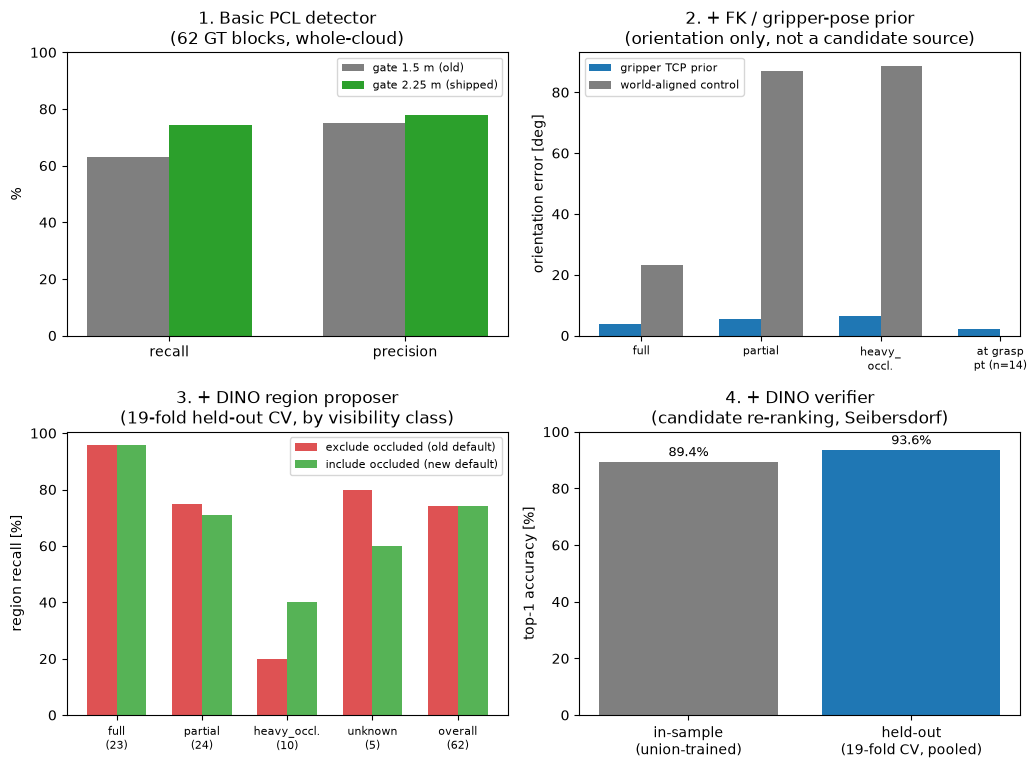

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.8))

# 1. Basic PCL detector: recall/precision, old vs shipped gate
ax = axes[0, 0]
labels = ["recall", "precision"]
old_gate = [62.9, 75.0]
shipped_gate = [74.2, 78.0]
x = np.arange(2); w = 0.35
ax.bar(x - w / 2, old_gate, w, label="gate 1.5 m (old)", color="tab:gray")
ax.bar(x + w / 2, shipped_gate, w, label="gate 2.25 m (shipped)", color="tab:green")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel("%"); ax.set_ylim(0, 100)
ax.set_title("1. Basic PCL detector\n(62 GT blocks, whole-cloud)")
ax.legend(fontsize=8)

# 2. FK / gripper prior: orientation error by visibility, vs world-aligned control
ax = axes[0, 1]
classes = ["full", "partial", "heavy_\noccl.", "at grasp\npt (n=14)"]
gripper_prior = [3.7, 5.5, 6.5, 2.3]
control = [23.3, 86.9, 88.7]
x = np.arange(len(classes)); w = 0.35
ax.bar(x - w / 2, gripper_prior, w, label="gripper TCP prior", color="tab:blue")
ax.bar(x[:3] + w / 2, control, w, label="world-aligned control", color="tab:gray")
ax.set_xticks(x); ax.set_xticklabels(classes, fontsize=8); ax.set_ylabel("orientation error [deg]")
ax.set_title("2. + FK / gripper-pose prior\n(orientation only, not a candidate source)")
ax.legend(fontsize=8)

# 3. DINO region proposer: recall by visibility, exclude vs include occluded blocks in training
ax = axes[1, 0]
classes = ["full\n(23)", "partial\n(24)", "heavy_occl.\n(10)", "unknown\n(5)", "overall\n(62)"]
excluded_arm = [95.7, 75.0, 20.0, 80.0, 74.2]
inclusive_arm = [95.7, 70.8, 40.0, 60.0, 74.2]
x = np.arange(len(classes)); w = 0.35
ax.bar(x - w / 2, excluded_arm, w, label="exclude occluded (old default)", color="tab:red", alpha=0.8)
ax.bar(x + w / 2, inclusive_arm, w, label="include occluded (new default)", color="tab:green", alpha=0.8)
ax.set_xticks(x); ax.set_xticklabels(classes, fontsize=8); ax.set_ylabel("region recall [%]")
ax.set_title("3. + DINO region proposer\n(19-fold held-out CV, by visibility class)")
ax.legend(fontsize=8)

# 4. DINO verifier: top-1 candidate re-ranking accuracy, in-sample vs genuinely held-out
ax = axes[1, 1]
labels = ["in-sample\n(union-trained)", "held-out\n(19-fold CV, pooled)"]
vals = [89.4, 93.6]
ax.bar(labels, vals, color=["tab:gray", "tab:blue"])
for i, v in enumerate(vals):
    ax.text(i, v + 2, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_ylabel("top-1 accuracy [%]"); ax.set_ylim(0, 100)
ax.set_title("4. + DINO verifier\n(candidate re-ranking, Seibersdorf)")

fig.tight_layout()
plt.show()

## 1. Basic PCL detector: the merged-cluster gate

Two blocks touching in a wall merge into one DBSCAN component. The old gate
(`cluster_max_extent_xy = 1.5 m`) dropped any component wider than that
*before a plane was ever fit* &mdash; rejecting both blocks outright. Raising
it to **2.25 m** (the measured knee of the recall/precision plateau, not a
tuned peak) recovered 7 of 11 over-gate blocks with **zero** regressions:
recall 62.9% &rarr; 74.2%, precision 75.0% &rarr; 78.0%. Below is one of the
recovered scenes.

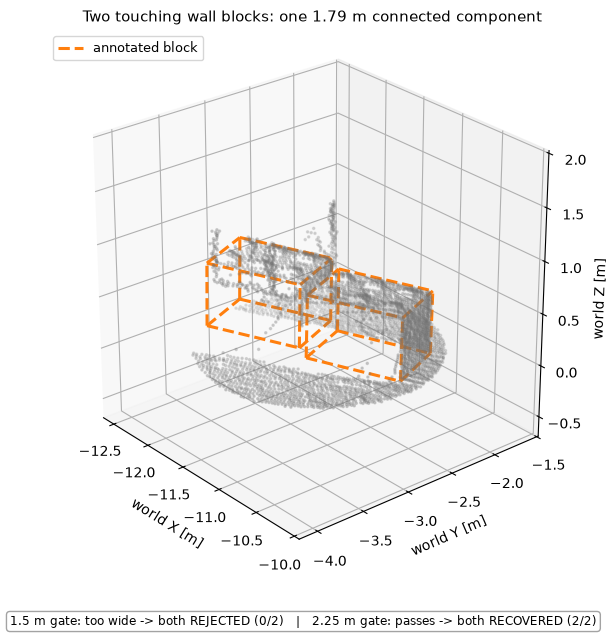

In [4]:
snap_dir = REPO_ROOT / "data/seibersdorf_dataset/2026_07_07_wall__1783429196_422551296"
tf = load_tf_snapshot(snap_dir / "tf.yaml")
points, _ = load_snapshot(
    snap_dir, REPO_ROOT / "config/transforms_pzs100_initial_pose_1.yaml",
    T_world_cloud=tf.T_world_cloud, require_registrations=False,
)
targets = [t for t in load_annotations(snap_dir / "annotations.yaml").targets if t.is_evaluation_target]
centre = np.mean([t.pose.position for t in targets], axis=0)
crop = (np.linalg.norm(points[:, :2] - centre[:2], axis=1) < 1.1) & (points[:, 2] < centre[2] + 0.8)
cropped = points[crop]

fig = plt.figure(figsize=(7.2, 6.4))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(cropped[:, 0], cropped[:, 1], cropped[:, 2], s=2.5, c="0.45", alpha=0.55)
plotted = [cropped]
for i, t in enumerate(targets):
    draw_pose(ax, t.pose, "tab:orange", "--", "annotated block" if i == 0 else None, plotted)
set_equal_3d(ax, plotted)
ax.set(xlabel="world X [m]", ylabel="world Y [m]", zlabel="world Z [m]")
ax.set_title("Two touching wall blocks: one 1.79 m connected component", fontsize=11)
ax.view_init(elev=26, azim=-40)
ax.legend(loc="upper left", fontsize=9)
fig.text(0.5, 0.02, "1.5 m gate: too wide -> both REJECTED (0/2)   |   2.25 m gate: passes -> both RECOVERED (2/2)",
         ha="center", fontsize=8.5, bbox=dict(boxstyle="round", fc="white", ec="0.6", alpha=0.9))
fig.subplots_adjust(bottom=0.12, top=0.95)
plt.show()

**Remaining gap.** Region-based fitting on the same 23 misses (seeded
fitter on a perfect ground-truth crop) recovers 16/23, an oracle ceiling of
(39+16)/62 = **88.7%** &mdash; SAM grid regions on real (non-oracle) proposals
recover only 7/23. Region *quality* dominates: perfect regions are worth 10
more blocks than SAM's, swapping the fitter itself is worth about 1. That gap
is what `dino_proposer` targets.

## 2. + FK / gripper-pose prior

The robot's own TCP orientation at grasp/placement time predicts a block's
yaw far better than a world-aligned guess, *especially* on the blocks whose
point cloud disagrees with itself most (87.8&deg; median refit disagreement
under `heavy_occlusion`) &mdash; see panel 2 above. But it does not help
*find* blocks: of the 14 blocks within 0.6 m of the FK grasp point the
detector already finds 12, and the 10 `heavy_occlusion` blocks sit a median
1.23 m from that point (hidden **by** the gripper, not held **by** it) so FK
gives no handle on their position at all. **Retired as a candidate
generator**; kept as a future orientation tie-breaker once a candidate
already exists from another source.

## 3. + DINO region proposer

`dino_proposer` predicts a high-recall 2-D region so the detector can fit
blocks the geometry gate above still misses. Its training target originally
excluded `heavy_occlusion`/`unknown` blocks (least-reliable labels) &mdash;
which meant it never saw a positive example of exactly the class it exists to
rescue. Measured both ways on identical 19-fold leave-one-scenario-out CV
(panel 3): including them **doubles** `heavy_occlusion` recall (20% &rarr;
40%) and quarters pooled false positives (8 &rarr; 2), for a small give-back
on `partial`/`unknown`. Now the default. One of the rescue-class snapshots:

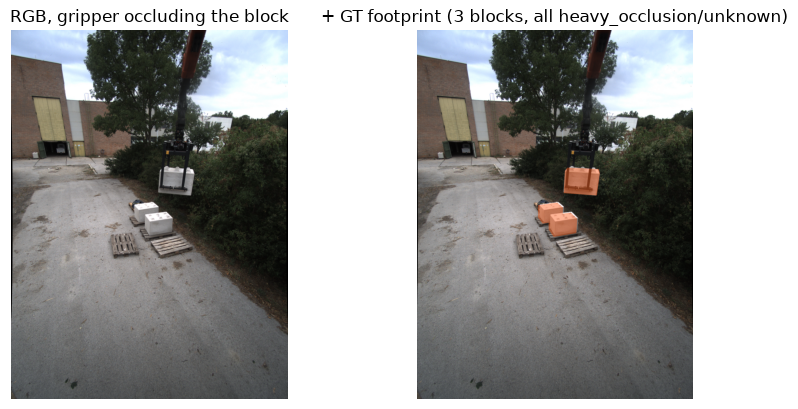

In [5]:
snap2_dir = REPO_ROOT / "data/seibersdorf_dataset/2026_07_07_grip_at_bottom_no_sides_high__1783428305_919404288"
camera = load_camera_model(REPO_ROOT / "config/calibration/calib_blackfly_to_seyond.yaml")
tf2 = load_tf_snapshot(snap2_dir / "tf.yaml")
targets2 = region_export.approved_targets(
    load_annotations(snap2_dir / "annotations.yaml"), occluded_visibilities=()
)
rgb = np.asarray(Image.open(snap2_dir / "rgb.png").convert("RGB"))

union = np.zeros(rgb.shape[:2], dtype=bool)
for t in targets2:
    mask = region_export.block_silhouette_mask(t.pose, tf2.T_world_camera, camera)
    if mask is not None:
        union |= mask

overlay = rgb.copy()
colour = np.array([255, 90, 20], dtype=np.uint8)
alpha = 0.45
overlay[union] = (overlay[union].astype(float) * (1 - alpha) + colour * alpha).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
axes[0].imshow(rgb); axes[0].set_title("RGB, gripper occluding the block"); axes[0].axis("off")
axes[1].imshow(overlay)
axes[1].set_title(f"+ GT footprint ({len(targets2)} blocks, all heavy_occlusion/unknown)")
axes[1].axis("off")
fig.tight_layout()
plt.show()

These are exactly the blocks `approved_targets()` used to drop from
the training union &mdash; the region head never saw a positive example of
this footprint shape until the default flipped.

### Why not just use SAM2?

SAM2 was tried first, as a zero-shot region source needing no training data
at all: prompt `facebook/sam2.1-hiera-small` with a fixed point grid per
image, project surviving masks to 3-D, and pool with the whole-cloud PCL
candidates. Re-measured at the current shipped gate (2.25 m; the original
report predates that change &mdash; see `experiments/sam_region_proposals.md`'s
own staleness note): baseline **46/62 (74.2%) recall, 46/59 (78.0%)
precision**; pooling SAM2's 8x8-grid regions in recovers 3 of the 16
remaining misses but adds **14** new false positives, landing at **49/62
(79.0%) recall, 49/74 (66.2%) precision** &mdash; roughly five new false
detections for every two true recoveries.

Grid density matters and isn't free: an informal sweep (old-gate config,
untuned, left panel below) shows a sparser 6x6 grid trading noticeably
better than the specified 8x8 default, and a denser 12x12 grid is worse on
*every* axis &mdash; more prompts means more redundant/spurious masks for
the fitter to filter, not more signal. `dino_proposer` moves in the opposite
direction on the same trade (right panel): trained on this project's own
annotations rather than prompted zero-shot, its occluded-inclusion decision
above *raised* recall on the rescue class while *cutting* pooled false
positives 8 &rarr; 2.

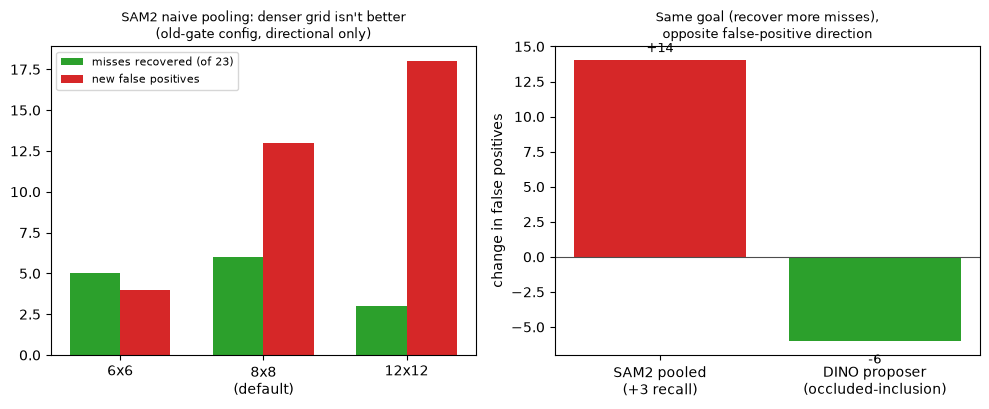

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

ax = axes[0]
grids = ["6x6", "8x8\n(default)", "12x12"]
recovered = [5, 6, 3]
new_fps = [4, 13, 18]
x = np.arange(3); w = 0.35
ax.bar(x - w / 2, recovered, w, label="misses recovered (of 23)", color="tab:green")
ax.bar(x + w / 2, new_fps, w, label="new false positives", color="tab:red")
ax.set_xticks(x); ax.set_xticklabels(grids)
ax.set_title("SAM2 naive pooling: denser grid isn't better\n(old-gate config, directional only)", fontsize=9.5)
ax.legend(fontsize=8)

ax = axes[1]
labels = ["SAM2 pooled\n(+3 recall)", "DINO proposer\n(occluded-inclusion)"]
fp_delta = [14, -6]
bars = ax.bar(labels, fp_delta, color=["tab:red", "tab:green"])
ax.axhline(0, color="0.3", linewidth=0.8)
for b, v in zip(bars, fp_delta):
    ax.text(b.get_x() + b.get_width() / 2, v + (0.6 if v >= 0 else -1.6), f"{v:+d}", ha="center", fontsize=9)
ax.set_ylabel("change in false positives")
ax.set_title("Same goal (recover more misses),\nopposite false-positive direction", fontsize=9.5)

fig.tight_layout()
plt.show()

SAM2 (and Mask2Former/Grounded-SAM) remain valid **offline annotation
and ablation tools** &mdash; useful for probing what a region-proposal
approach *could* recover before spending training effort &mdash; but
`docs/dino-rgb-prior-ros-integration.md` deliberately excludes them from the
runtime path. `dino_proposer` is the one trained for it: a compact head on a
frozen backbone, fit to this project's own occlusion patterns instead of
prompted generically, is what let the false-positive trade-off run in the
useful direction.

## 4. + DINO verifier

`dino_verifier` re-ranks fitted candidates using pooled DINOv2 features under
each candidate's projected interior/edge/exterior/gripper-occlusion regions.
Retrained on the same Seibersdorf dataset and fold splits as `dino_proposer`
(the original checkpoint was trained on a different, older dataset). Top-1
accuracy at picking the correct candidate: **93.6%** (44/47), genuinely
held-out &mdash; pooled across the same 19-fold leave-one-scenario-out CV,
each prediction from a head that never trained on its own fold &mdash;
against **89.4%** (42/47) for the union-trained checkpoint actually shipped
(panel 4 above; see `models/production/README.md` for exact provenance). The
geometry-ordering baseline used previously isn't well-formed on this export
(0 candidate sets have both a scored pair and a labelled raw hypothesis), so
it is omitted here rather than reported misleadingly.

## Status & how to reproduce

| stage | wired into the C++ detector? | measured on |
| --- | --- | --- |
| PCL geometric detector | yes, shipped | 62 GT blocks, whole-cloud |
| FK / gripper prior | orientation-only utility exists; not consumed as a tie-breaker yet | 59 blocks with rail TF |
| `dino_proposer` | no &mdash; standalone region-recall metric only | 19-fold held-out CV, 62 blocks |
| `dino_verifier` | no &mdash; standalone re-ranking metric only | 19-fold held-out CV, 47 candidate sets |

Both heads' shipped checkpoints and the frozen DINOv2-small backbone are
vendored in `models/production/` (see its README for provenance and offline
usage) &mdash; committed artifacts, still not wired into the runtime path.

None of the four numbers above compose into one end-to-end pipeline result
yet. `docs/dino-rgb-prior-ros-integration.md` specifies the ablation to run
once they are wired: `geometry` &rarr; `+FK` &rarr; `+dino_proposer` &rarr;
`+dino_proposer+dino_verifier`, each on the same held-out bags.

Reproduce:

```bash
python tools/sweep_detector_params.py                       # panel 1
python -m experiments.rgb_region_prior.export --export-root out/rgb_region_prior_all --occluded-visibilities none
python -m experiments.rgb_region_prior.train  --export-root out/rgb_region_prior_all --held-out-fold N --checkpoint-out out/ckpt_foldN
python -m experiments.rgb_region_prior.report --export-root out/rgb_region_prior_all --held-out-fold N --checkpoint out/ckpt_foldN  # panel 3
python -m experiments.rgb_candidate_prior.export --export-root out/rgb_candidate_prior_seibersdorf --snapshots-dir data/seibersdorf_dataset
python -m experiments.rgb_candidate_prior.train  --export-root out/rgb_candidate_prior_seibersdorf --splits config/rgb_ablation_splits_seibersdorf.yaml --checkpoint-out out/dino_verifier_checkpoint  # panel 4
```

See `experiments/detector_cluster_failures.md`,
`experiments/pose_quality_and_partial_observation.md`, and
`docs/dino-rgb-prior-ros-integration.md` for full detail and caveats.